In [ ]:
# Load Data
!pip install -q pyreadr
!git clone -q https://github.com/warint/tiger_woods.git

import pandas as pd
import pyreadr
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

df = pyreadr.read_r("tiger_woods/data/old/tiger_woods_sentiment.RDS")[None]
print(df.shape)
df.head()

fatal: destination path 'tiger_woods' already exists and is not an empty directory.
(1284, 39)


,Tour,Tournament_Year,Tournament_Order,Permanent_Tournament_Number,Course_Number,Player_Number,Player_Name,Round_Number,Event_Name,Course_Name,...,Strokes_gained_v_a_v_Leader,Distance_to_runner_up_strokes_,Strokes_gained_v_a_v_Runner_up,Minor_Injury,Major_injury_surgery,Personal_issues,Major,Prize_Money,SoF,OWGR
0,R,1996.0,150.0,14.0,14.0,8793.0,"Woods, Tiger",1.0,Masters Tournament,Augusta National GC,...,NaN,NaN,NaN,0.0,0.0,0.0,1.0,2347895.0,694.0,612.0
1,R,1996.0,150.0,14.0,14.0,8793.0,"Woods, Tiger",2.0,Masters Tournament,Augusta National GC,...,6.0,NaN,NaN,0.0,0.0,0.0,1.0,2347895.0,694.0,612.0
2,R,1996.0,240.0,26.0,628.0,8793.0,"Woods, Tiger",1.0,U.S. Open Championship,Oakland Hills CC,...,NaN,NaN,NaN,0.0,0.0,0.0,1.0,2542705.0,664.0,619.0
3,R,1996.0,240.0,26.0,628.0,8793.0,"Woods, Tiger",2.0,U.S. Open Championship,Oakland Hills CC,...,-2.0,NaN,NaN,0.0,0.0,0.0,1.0,2542705.0,664.0,619.0
4,R,1996.0,240.0,26.0,628.0,8793.0,"Woods, Tiger",3.0,U.S. Open Championship,Oakland Hills CC,...,7.0,NaN,NaN,0.0,0.0,0.0,1.0,2542705.0,664.0,619.0


In [ ]:
# Preprocessing

# Next round's score (within the same tournament)
df = df.sort_values(["Tournament_Year", "Tournament_Order", "Round_Number"])
df["next_score"] = df.groupby(["Tournament_Year", "Permanent_Tournament_Number"])["Round_Score"].shift(-1)

# Missing values: drop rows with no interview text or no next round
df["Interview_Text"] = df["Interview_Text"].fillna("").str.strip()
df = df[df["Interview_Text"] != ""]
df = df.dropna(subset=["next_score"])

# Encoding: make the label 0/1
df["label"] = (df["next_score"] <= 69).astype(int)

# Unscaled copy of sentiment for the EDA plot
df["sentiment_raw"] = df["Response_Sentiment"]

# Normalization: scale a few numeric features
num_cols = ["Round_Score", "OWGR", "Response_Sentiment"]
df[num_cols] = StandardScaler().fit_transform(df[num_cols])

# Word count (for EDA)
df["words"] = df["Interview_Text"].str.split().str.len()

print("Usable examples:", len(df))
df[["Tournament_Year", "Round_Number", "next_score", "label", "words"]].head()

Usable examples: 380


,Tournament_Year,Round_Number,next_score,label,words
0,1996.0,1.0,75.0,0,407
33,1996.0,1.0,78.0,0,47
34,1996.0,2.0,72.0,0,122
79,1997.0,1.0,67.0,1,38
80,1997.0,2.0,73.0,0,25


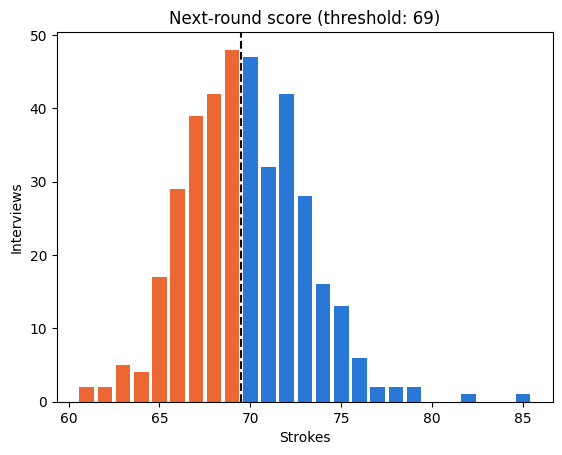

label
0    192
1    188
Name: count, dtype: int64


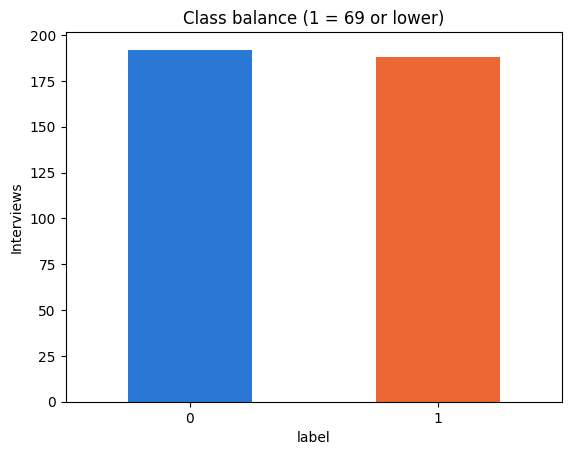

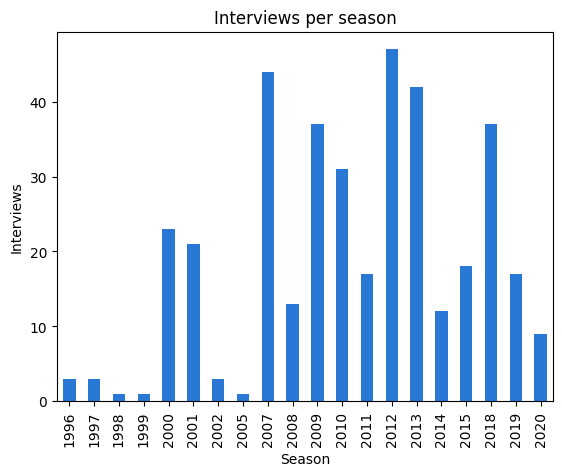

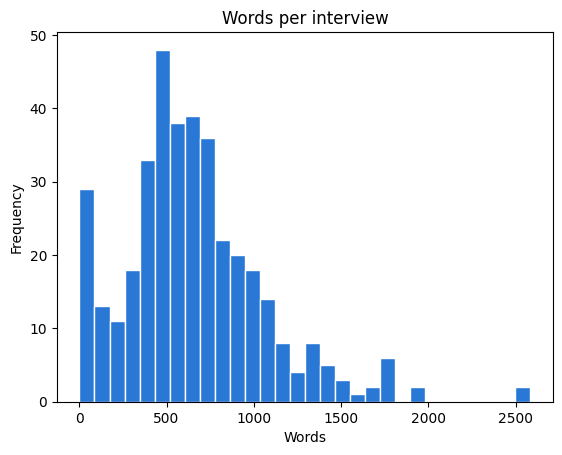

count     380.000000
mean      654.652632
std       406.566348
min         1.000000
25%       411.500000
50%       604.000000
75%       846.500000
max      2584.000000
Name: words, dtype: float64
Share longer than ~380 words (512 tokens): 0.78
Correlation with label:
Round_Score     -0.25
OWGR            -0.02
sentiment_raw    0.01
words            0.16
label            1.00
Name: label, dtype: float64

Share breaking 70 at majors (1) vs other events (0):
Major
0.0    0.56
1.0    0.31
Name: label, dtype: float64

Share breaking 70 with personal issues (1) vs without (0):
                 mean  count
Personal_issues             
0.0              0.51    361
1.0              0.21     19


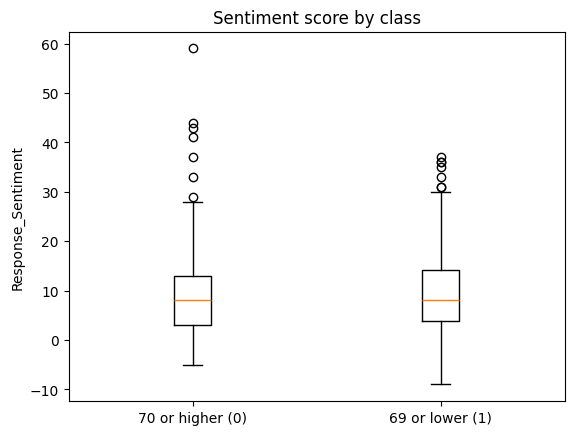

Median sentiment by class:
label
0    8.0
1    8.0
Name: sentiment_raw, dtype: float64
1996 Masters Tournament, round 1, label 0
Overall it was pretty good,  No, not really. I had a nice putt at it. Unfortunately, I had to chip it because there was a drain in the green, but I hit a bad chip, but hit a good putt; unfortunately hit a bad tee shot the next hole,  I thought I had a good shot playing left to the hole trying to use the slope, bring it back into the hole, hit it right where I was aiming, right at my spot. Unfortunately, it wasn't enough stick,  Put it this way, a lot of work ahead of me tomorrow. I have got to p


In [ ]:
# Exploratory Data Analysis

# Colors
BLUE, ORANGE = "#2a78d6", "#eb6834"

# Next-round score distribution (orange = 69 or lower)
counts = df["next_score"].value_counts().sort_index()
colors = [ORANGE if s <= 69 else BLUE for s in counts.index]
plt.bar(counts.index, counts.values, color=colors)
plt.axvline(69.5, color="black", linestyle="--")
plt.title("Next-round score (threshold: 69)")
plt.xlabel("Strokes")
plt.ylabel("Interviews")
plt.show()

# Class balance
print(df["label"].value_counts())
df["label"].value_counts().sort_index().plot(kind="bar", color=[BLUE, ORANGE])
plt.title("Class balance (1 = 69 or lower)")
plt.ylabel("Interviews")
plt.xticks(rotation=0)
plt.show()

# Interviews per season
df["Tournament_Year"].astype(int).value_counts().sort_index().plot(kind="bar", color=BLUE)
plt.title("Interviews per season")
plt.xlabel("Season")
plt.ylabel("Interviews")
plt.show()

# Words per interview
df["words"].plot(kind="hist", bins=30, color=BLUE, edgecolor="white")
plt.title("Words per interview")
plt.xlabel("Words")
plt.show()
print(df["words"].describe())
print("Share longer than ~380 words (512 tokens):", round((df["words"] > 380).mean(), 2))

# Feature importance table
print("Correlation with label:")
print(df[["Round_Score", "OWGR", "sentiment_raw", "words", "label"]].corr()["label"].round(2))
print("\nShare breaking 70 at majors (1) vs other events (0):")
print(df.groupby("Major")["label"].mean().round(2))
print("\nShare breaking 70 with personal issues (1) vs without (0):")
print(df.groupby("Personal_issues")["label"].agg(["mean", "count"]).round(2))

# Sentiment score by class
plt.boxplot([df.loc[df["label"] == 0, "sentiment_raw"], df.loc[df["label"] == 1, "sentiment_raw"]],
            tick_labels=["70 or higher (0)", "69 or lower (1)"])
plt.title("Sentiment score by class")
plt.ylabel("Response_Sentiment")
plt.show()
print("Median sentiment by class:")
print(df.groupby("label")["sentiment_raw"].median())

# Sample interview
row = df.iloc[0]
print(f"{int(row.Tournament_Year)} {row.Event_Name}, round {int(row.Round_Number)}, label {row.label}")
print(row.Interview_Text[:500])